# Lab 05: Polynomial Regression
This notebook covers **Lab Task 01** (single feature) and **Lab Task 02** (multiple features).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score

np.random.seed(42)

---
# Lab Task 01: Polynomial Regression with a Single Feature

## 1. Load the dataset
We generate a single-feature dataset with a curved (non-linear) relationship plus noise, so no CSV file is needed.

*If you prefer the lab's `Position_Salaries.csv`, replace this cell with `dataset = pd.read_csv('Position_Salaries.csv')`, `X = dataset.iloc[:,1:2].values`, `y = dataset.iloc[:,2].values`.*

In [2]:
n = 100
X = np.sort(np.random.uniform(0, 10, n)).reshape(-1, 1)
y = 2 * X.ravel()**3 - 25 * X.ravel()**2 + 80 * X.ravel() + 50 + np.random.normal(0, 20, n)

df1 = pd.DataFrame({'x': X.ravel(), 'y': y})
display(df1.head())
print(df1.describe())

,x,y
0,0.055221,56.082737
1,0.205845,59.445589
2,0.254191,70.588035
3,0.343885,34.884346
4,0.452273,76.859650


                x           y
count  100.000000  100.000000
mean     4.701807  115.257834
std      2.974894   61.542013
min      0.055221   29.540786
25%      1.932008   78.236748
50%      4.641425  107.068287
75%      7.302031  125.993943
max      9.868869  343.537475


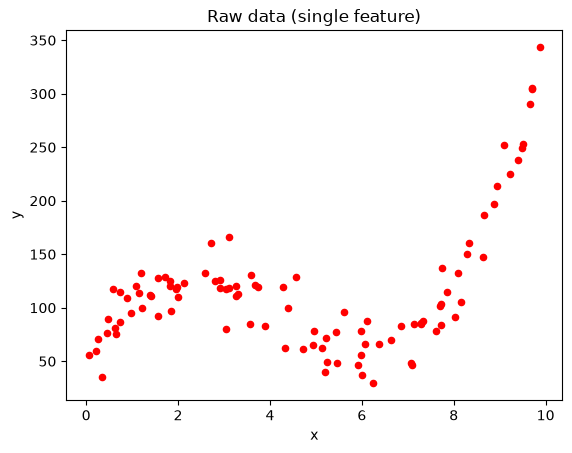

In [3]:
plt.scatter(X, y, color='red', s=20)
plt.title('Raw data (single feature)')
plt.xlabel('x'); plt.ylabel('y')
plt.show()

## 2. Train/test split

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Train size:', X_train.shape[0], '| Test size:', X_test.shape[0])

Train size: 80 | Test size: 20


## 3. Fit polynomial regression (chosen degree = 3, cubic)

In [5]:
degree = 3
poly = PolynomialFeatures(degree=degree)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

model = LinearRegression()
model.fit(X_train_poly, y_train)
print('Coefficients:', model.coef_)
print('Intercept   :', model.intercept_)

Coefficients: [  0.          83.67184269 -25.68739498   2.0416543 ]
Intercept   : 43.357732104199485


## 4. Predict on test data and evaluate

In [6]:
y_pred = model.predict(X_test_poly)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f'Degree {degree}')
print(f'MSE  : {mse:.2f}')
print(f'RMSE : {rmse:.2f}')
print(f'R^2  : {r2:.4f}')

Degree 3
MSE  : 276.56
RMSE : 16.63
R^2  : 0.8023


## 5. Visualize the fitted curve with the data points

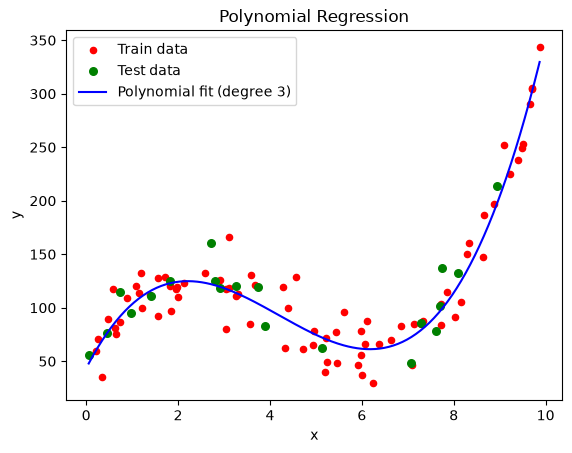

In [7]:
X_grid = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)
y_grid = model.predict(poly.transform(X_grid))

plt.scatter(X_train, y_train, color='red', s=20, label='Train data')
plt.scatter(X_test, y_test, color='green', s=30, label='Test data')
plt.plot(X_grid, y_grid, color='blue', label=f'Polynomial fit (degree {degree})')
plt.title('Polynomial Regression')
plt.xlabel('x'); plt.ylabel('y')
plt.legend()
plt.show()

## 6. Experiment with different degrees
We compare a straight line (degree 1) against higher degrees and track train vs test error.

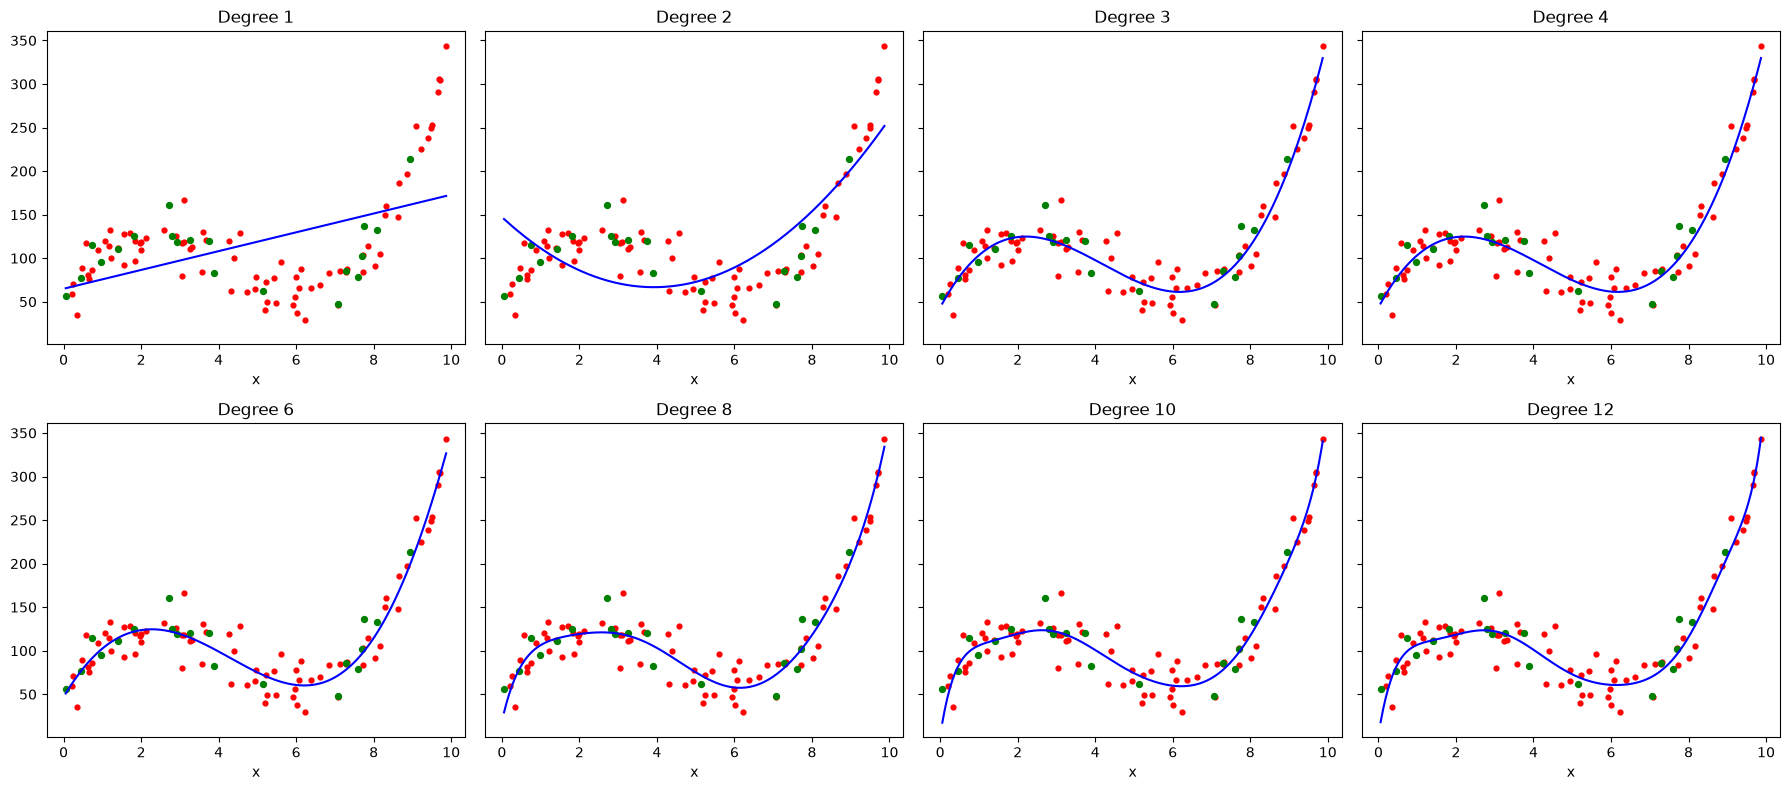

,Degree,Train MSE,Test MSE,Train R2,Test R2
0,1,3296.872,1871.313,0.237,-0.338
1,2,1722.765,2157.364,0.601,-0.542
2,3,340.949,276.560,0.921,0.802
3,4,340.948,276.774,0.921,0.802
4,6,339.832,266.674,0.921,0.809
5,8,329.748,298.544,0.924,0.787
6,10,325.767,318.782,0.925,0.772
7,12,320.604,320.495,0.926,0.771


In [8]:
degrees = [1, 2, 3, 4, 6, 8, 10, 12]
rows = []

fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharey=True)
for ax, d in zip(axes.ravel(), degrees):
    pipe = make_pipeline(PolynomialFeatures(d), StandardScaler(), LinearRegression())
    pipe.fit(X_train, y_train)

    tr_pred = pipe.predict(X_train)
    te_pred = pipe.predict(X_test)
    rows.append({
        'Degree': d,
        'Train MSE': mean_squared_error(y_train, tr_pred),
        'Test MSE': mean_squared_error(y_test, te_pred),
        'Train R2': r2_score(y_train, tr_pred),
        'Test R2': r2_score(y_test, te_pred),
    })

    ax.scatter(X_train, y_train, color='red', s=12)
    ax.scatter(X_test, y_test, color='green', s=18)
    ax.plot(X_grid, pipe.predict(X_grid), color='blue')
    ax.set_title(f'Degree {d}')
    ax.set_xlabel('x')
plt.tight_layout()
plt.show()

results1 = pd.DataFrame(rows).round(3)
results1

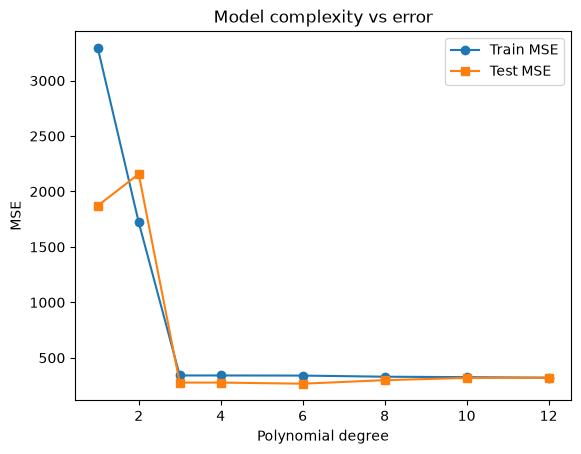

In [9]:
plt.plot(results1['Degree'], results1['Train MSE'], 'o-', label='Train MSE')
plt.plot(results1['Degree'], results1['Test MSE'], 's-', label='Test MSE')
plt.xlabel('Polynomial degree'); plt.ylabel('MSE')
plt.title('Model complexity vs error')
plt.legend()
plt.show()

## 7. Discussion: underfitting vs overfitting

- **Underfitting (degree 1, and sometimes 2):** The model is too simple to capture the curve. Both train and test errors are high and R² is low. This is *high bias*.
- **Good fit (around degree 3):** Train and test errors are both low and close to each other. The model matches the true shape of the data.
- **Overfitting (very high degrees, e.g. 10 and 12):** Train error keeps shrinking because the curve starts following the noise, but test error stops improving or rises, and the curve gets wiggly near the edges. This is *high variance*.
- **Trade-off:** Increasing the degree lowers bias but raises variance. The best degree is the one where **test error is lowest**, not train error. Techniques like cross-validation, regularization (Ridge/Lasso) and keeping the degree low help control overfitting.

*(Check the table and plot above and adjust these statements to match your exact numbers.)*

---
# Lab Task 02: Polynomial Regression with Multiple Features

## 1. Load the dataset
We use the **California Housing** dataset from scikit-learn (8 features, target = median house value). If it cannot be downloaded (no internet), the cell falls back to the built-in **Diabetes** dataset.

In [10]:
from sklearn.datasets import fetch_california_housing, load_diabetes

try:
    data = fetch_california_housing(as_frame=True)
    name = 'California Housing'
    target_name = 'MedHouseVal'
except Exception as e:
    print('Could not download California Housing, using Diabetes instead:', e)
    data = load_diabetes(as_frame=True)
    name = 'Diabetes'
    target_name = 'target'

df = data.frame.copy()
print('Dataset:', name, '| Shape:', df.shape)
df.head()

Dataset: California Housing | Shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## 2. Explore the dataset

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [12]:
print('Missing values per column:\n', df.isnull().sum())
df.describe().T

Missing values per column:
 MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


In [13]:
corr = df.corr()[target_name].drop(target_name).sort_values(key=abs, ascending=False)
print('Correlation of each feature with the target:')
print(corr.round(3))

Correlation of each feature with the target:
MedInc        0.688
AveRooms      0.152
Latitude     -0.144
HouseAge      0.106
AveBedrms    -0.047
Longitude    -0.046
Population   -0.025
AveOccup     -0.024
Name: MedHouseVal, dtype: float64


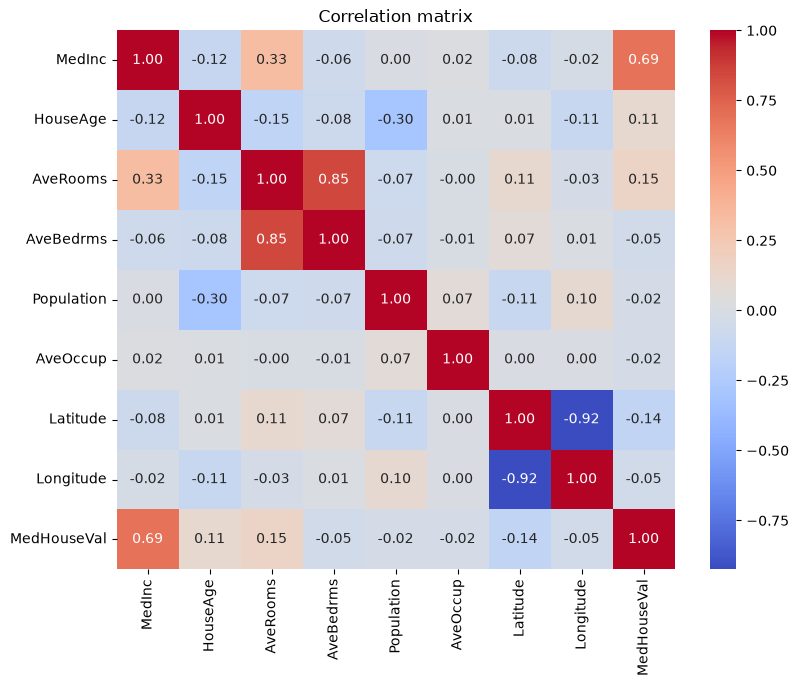

In [14]:
# Heatmap of correlations
import seaborn as sns
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation matrix')
plt.show()

## 3. Visualize the data to look for non-linear patterns
We plot the top 4 features against the target with a straight line (red) and a quadratic curve (green) so curvature is easy to spot.

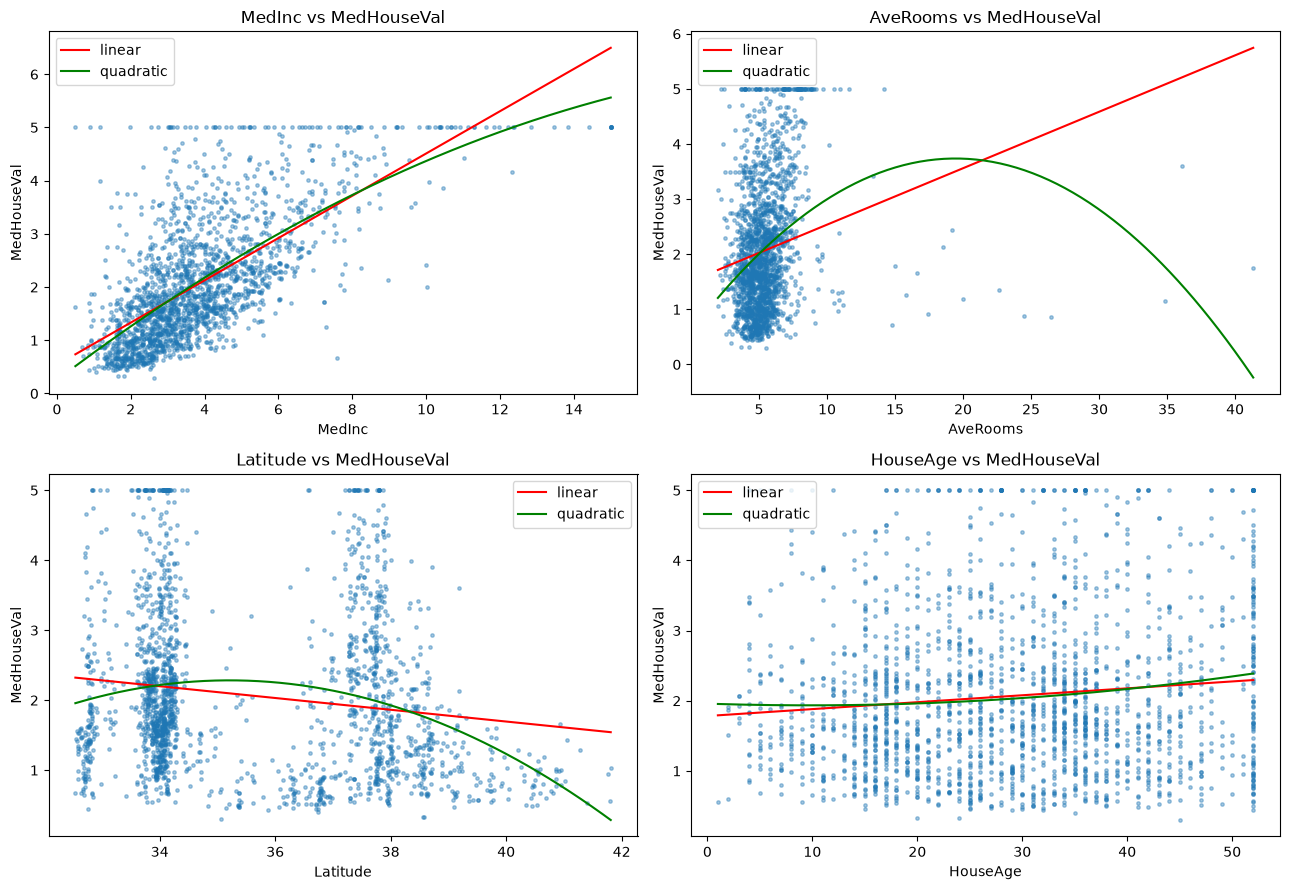

In [15]:
top_features = corr.index[:4].tolist()
sample = df.sample(min(2000, len(df)), random_state=42)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, f in zip(axes.ravel(), top_features):
    ax.scatter(sample[f], sample[target_name], s=6, alpha=0.4)
    xs = np.linspace(sample[f].min(), sample[f].max(), 200)
    ax.plot(xs, np.polyval(np.polyfit(sample[f], sample[target_name], 1), xs), 'r', label='linear')
    ax.plot(xs, np.polyval(np.polyfit(sample[f], sample[target_name], 2), xs), 'g', label='quadratic')
    ax.set_xlabel(f); ax.set_ylabel(target_name)
    ax.set_title(f'{f} vs {target_name}')
    ax.legend()
plt.tight_layout()
plt.show()

## 4. Preprocessing
Split into train/test sets. Scaling is done inside the pipeline later, because polynomial terms can become very large and unbalanced without it.

In [16]:
X_all = df.drop(columns=[target_name])
y_all = df[target_name]

X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=0.2, random_state=42)
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (16512, 8) | Test: (4128, 8)


## 5. Polynomial feature engineering
We pick the 3 most correlated features and create quadratic (degree 2) terms: squares and pairwise interactions.

In [17]:
selected = corr.index[:3].tolist()
print('Selected features:', selected)

degree = 2
poly = PolynomialFeatures(degree=degree, include_bias=False)
Xtr_sel_poly = poly.fit_transform(X_train[selected])
Xte_sel_poly = poly.transform(X_test[selected])

new_names = poly.get_feature_names_out(selected)
print('Engineered features:', list(new_names))
print('Shape after transform:', Xtr_sel_poly.shape)

poly_df = pd.DataFrame(Xtr_sel_poly, columns=new_names, index=X_train.index)
poly_df.head()

Selected features: ['MedInc', 'AveRooms', 'Latitude']
Engineered features: ['MedInc', 'AveRooms', 'Latitude', 'MedInc^2', 'MedInc AveRooms', 'MedInc Latitude', 'AveRooms^2', 'AveRooms Latitude', 'Latitude^2']
Shape after transform: (16512, 9)


,MedInc,AveRooms,Latitude,MedInc^2,MedInc AveRooms,MedInc Latitude,AveRooms^2,AveRooms Latitude,Latitude^2
14196,3.2596,5.017657,32.71,10.624992,16.355553,106.621516,25.176877,164.127544,1069.9441
8267,3.8125,4.473545,33.77,14.535156,17.055390,128.748125,20.012605,151.071614,1140.4129
17445,4.1563,5.645833,34.66,17.274830,23.465777,144.057358,31.875434,195.684583,1201.3156
14265,1.9425,4.002817,32.69,3.773306,7.775472,63.500325,16.022543,130.852085,1068.6361
2271,3.5542,6.268421,36.78,12.632338,22.279222,130.723476,39.293102,230.552526,1352.7684


MedInc               0.691
MedInc Latitude      0.677
MedInc^2             0.627
MedInc AveRooms      0.571
AveRooms             0.158
Latitude^2          -0.147
Latitude            -0.143
AveRooms Latitude    0.127
AveRooms^2           0.037
Name: MedHouseVal, dtype: float64


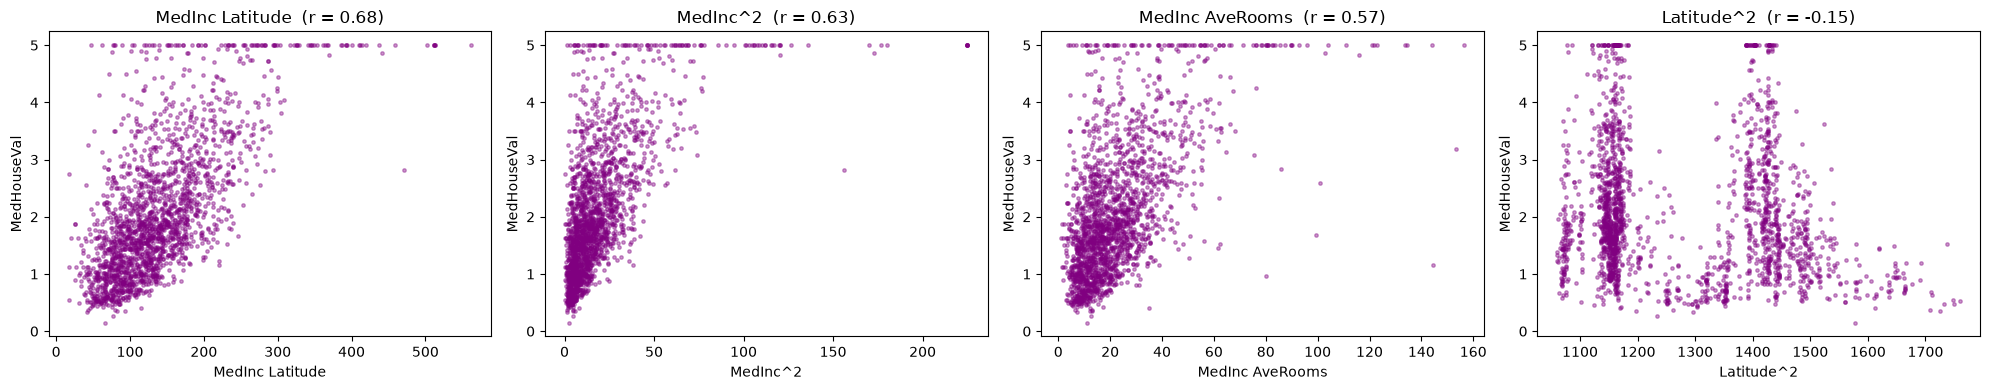

In [18]:
# Relationship of the engineered features with the target
engineered = poly_df.copy()
engineered[target_name] = y_train
eng_corr = engineered.corr()[target_name].drop(target_name).sort_values(key=abs, ascending=False)
print(eng_corr.round(3))

top_new = [c for c in eng_corr.index if c not in selected][:4]
fig, axes = plt.subplots(1, len(top_new), figsize=(5 * len(top_new), 4))
axes = np.atleast_1d(axes)
for ax, c in zip(axes, top_new):
    s = engineered.sample(min(2000, len(engineered)), random_state=1)
    ax.scatter(s[c], s[target_name], s=6, alpha=0.4, color='purple')
    ax.set_xlabel(c); ax.set_ylabel(target_name)
    ax.set_title(f'{c}  (r = {eng_corr[c]:.2f})')
plt.tight_layout()
plt.show()

## 6. Train the polynomial regression model and predict

In [19]:
model2 = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    StandardScaler(),
    LinearRegression()
)
# Use only the selected features for the polynomial expansion
model2.fit(X_train[selected], y_train)

y_pred_train = model2.predict(X_train[selected])
y_pred_test = model2.predict(X_test[selected])
print('Model trained on', len(selected), 'features ->', model2[0].n_output_features_, 'polynomial terms')

Model trained on 3 features -> 9 polynomial terms


## 7. Evaluate

In [20]:
def report(label, y_true, y_hat):
    mse = mean_squared_error(y_true, y_hat)
    print(f'{label:6s} | MSE: {mse:.4f} | RMSE: {np.sqrt(mse):.4f} | R2: {r2_score(y_true, y_hat):.4f}')

report('Train', y_train, y_pred_train)
report('Test', y_test, y_pred_test)

# Baseline: plain linear regression on the same features
base = LinearRegression().fit(X_train[selected], y_train)
report('Linear', y_test, base.predict(X_test[selected]))

Train  | MSE: 0.6519 | RMSE: 0.8074 | R2: 0.5123
Test   | MSE: 0.6880 | RMSE: 0.8294 | R2: 0.4750
Linear | MSE: 0.6942 | RMSE: 0.8332 | R2: 0.4703


## 8. Visualize predictions vs actual values

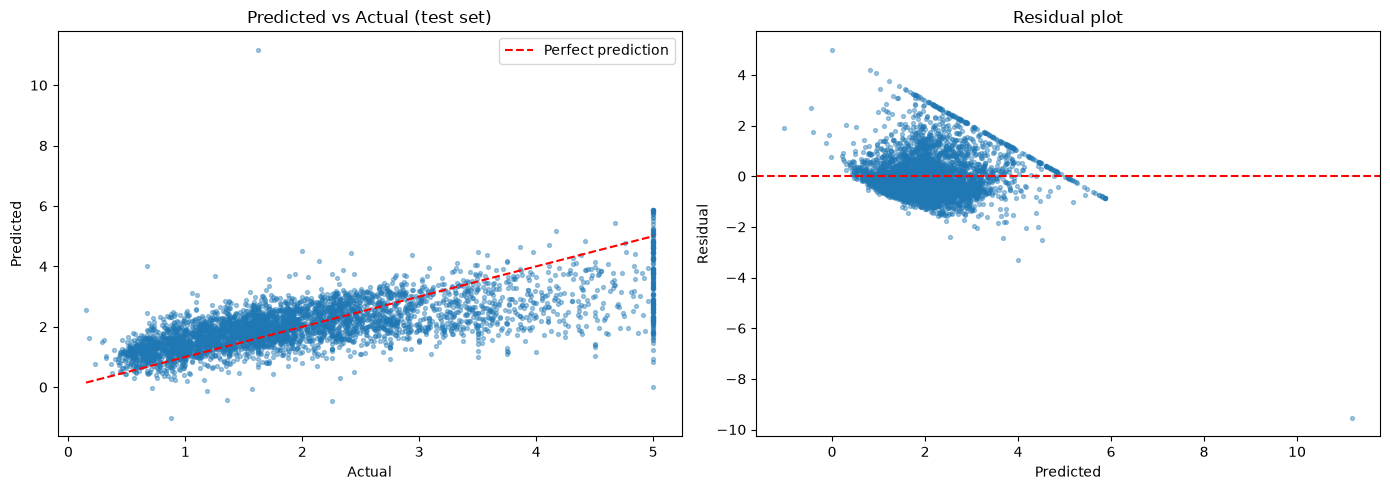

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test, y_pred_test, s=8, alpha=0.4)
lims = [y_test.min(), y_test.max()]
axes[0].plot(lims, lims, 'r--', label='Perfect prediction')
axes[0].set_xlabel('Actual'); axes[0].set_ylabel('Predicted')
axes[0].set_title('Predicted vs Actual (test set)')
axes[0].legend()

residuals = y_test - y_pred_test
axes[1].scatter(y_pred_test, residuals, s=8, alpha=0.4)
axes[1].axhline(0, color='r', linestyle='--')
axes[1].set_xlabel('Predicted'); axes[1].set_ylabel('Residual')
axes[1].set_title('Residual plot')
plt.tight_layout()
plt.show()

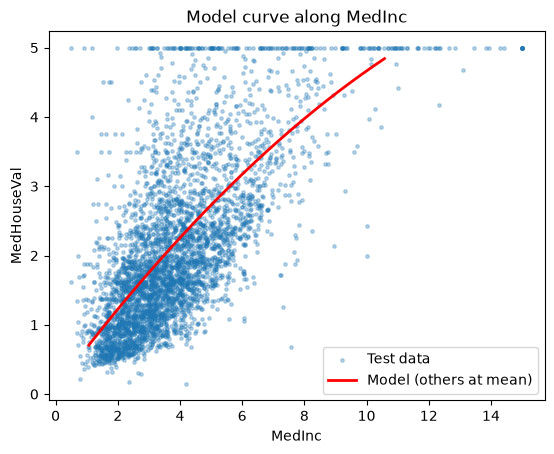

In [22]:
# Fit curve for the single strongest feature, holding the others at their mean
f0 = selected[0]
grid = pd.DataFrame({c: np.full(200, X_train[c].mean()) for c in selected})
grid[f0] = np.linspace(X_train[f0].quantile(0.01), X_train[f0].quantile(0.99), 200)

plt.scatter(X_test[f0], y_test, s=6, alpha=0.3, label='Test data')
plt.plot(grid[f0], model2.predict(grid[selected]), color='red', linewidth=2, label='Model (others at mean)')
plt.xlabel(f0); plt.ylabel(target_name)
plt.title(f'Model curve along {f0}')
plt.legend()
plt.show()

## 9. Experiment with different degrees

In [23]:
rows = []
for d in [1, 2, 3, 4, 5]:
    m = make_pipeline(PolynomialFeatures(d, include_bias=False), StandardScaler(), LinearRegression())
    m.fit(X_train[selected], y_train)
    tr, te = m.predict(X_train[selected]), m.predict(X_test[selected])
    rows.append({
        'Degree': d,
        'No. of terms': m[0].n_output_features_,
        'Train MSE': mean_squared_error(y_train, tr),
        'Test MSE': mean_squared_error(y_test, te),
        'Train R2': r2_score(y_train, tr),
        'Test R2': r2_score(y_test, te),
    })
results2 = pd.DataFrame(rows).round(4)
results2

,Degree,No. of terms,Train MSE,Test MSE,Train R2,Test R2
0,1,3,0.6825,0.6942,0.4895,0.4703
1,2,9,0.6519,0.6880,0.5123,0.4750
2,3,19,0.6210,0.6516,0.5355,0.5028
3,4,34,0.6019,1.1772,0.5497,0.1017
4,5,55,0.5937,127.5844,0.5559,-96.3623


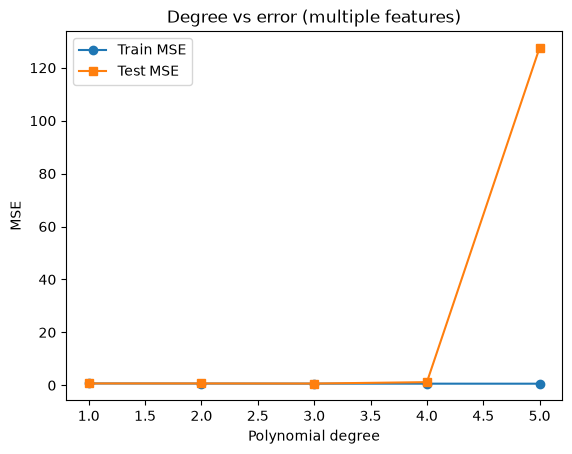

In [24]:
plt.plot(results2['Degree'], results2['Train MSE'], 'o-', label='Train MSE')
plt.plot(results2['Degree'], results2['Test MSE'], 's-', label='Test MSE')
plt.xlabel('Polynomial degree'); plt.ylabel('MSE')
plt.title('Degree vs error (multiple features)')
plt.legend()
plt.show()

## 10. Feature selection matters: all features vs selected features

In [25]:
rows = []
for label, cols in [('Top 3 features', selected), ('All features', list(X_all.columns))]:
    for d in [1, 2, 3]:
        m = make_pipeline(PolynomialFeatures(d, include_bias=False), StandardScaler(), LinearRegression())
        m.fit(X_train[cols], y_train)
        rows.append({
            'Features': label, 'Degree': d,
            'No. of terms': m[0].n_output_features_,
            'Train R2': r2_score(y_train, m.predict(X_train[cols])),
            'Test R2': r2_score(y_test, m.predict(X_test[cols])),
        })
pd.DataFrame(rows).round(4)

,Features,Degree,No. of terms,Train R2,Test R2
0,Top 3 features,1,3,0.4895,0.4703
1,Top 3 features,2,9,0.5123,0.4750
2,Top 3 features,3,19,0.5355,0.5028
3,All features,1,8,0.6126,0.5758
4,All features,2,44,0.6853,0.6457
5,All features,3,164,0.7436,-17.9290


## 11. Regularization: taming high-degree models (optional but useful)

In [26]:
cols = list(X_all.columns)
rows = []
for d in [2, 3, 4]:
    for name, reg in [('OLS', LinearRegression()), ('Ridge', Ridge(alpha=10))]:
        m = make_pipeline(PolynomialFeatures(d, include_bias=False), StandardScaler(), reg)
        m.fit(X_train[cols], y_train)
        rows.append({'Degree': d, 'Model': name,
                     'Train R2': r2_score(y_train, m.predict(X_train[cols])),
                     'Test R2': r2_score(y_test, m.predict(X_test[cols]))})
pd.DataFrame(rows).round(4)

,Degree,Model,Train R2,Test R2
0,2,OLS,0.6853,0.6457
1,2,Ridge,0.6572,0.6192
2,3,OLS,0.7436,-17.9290
3,3,Ridge,0.6925,0.5062
4,4,OLS,0.7647,-905.1628
5,4,Ridge,0.7077,-0.4786


## 12. Discussion and conclusions

**Insights from the analysis**
- The exploratory plots showed that some features (for example median income) have a curved relationship with the target, so a straight line cannot capture all of it. Polynomial terms let a *linear* model fit those curves.
- Degree 2 usually gives a clear gain in test R² over plain linear regression. The interaction terms (e.g. `feature1 * feature2`) capture how features work together.

**Effect of the polynomial degree**
- Low degree (1): underfits, with high bias and low R².
- Moderate degree (2 to 3): best balance, where test error is lowest or close to it.
- High degree (4 and above): the number of terms explodes (it grows combinatorially with the number of features). Train error keeps falling while test error stops improving or gets worse, which is overfitting.

**Importance of feature selection**
- Expanding all features to a high degree creates hundreds of terms, many of them noise, which increases training time and the risk of overfitting.
- Choosing the most relevant features first (using correlation or domain knowledge) keeps the model smaller and easier to interpret, often with similar accuracy.

**Trade-offs**
- Complexity vs generalization: more terms fit the training data better but may predict new data worse.
- Accuracy vs interpretability: simple low-degree models are easy to explain; high-degree models are not.
- Regularization (Ridge/Lasso) and cross-validation are practical ways to choose a degree and keep high-degree models stable.

*(Update the statements above to match the numbers in your own result tables.)*